# Toy IFCB likelihood workflow

This notebook demonstrates the proposed concentration-estimation workflow in a deliberately simple setting.

Each sample has 100 analysis-time bins. A target particle has a characteristic arrival distribution across those bins. When a particle is imaged, the IFCB is inhibited for one subsequent bin. The notebook compares: 

1. the true concentration used in simulation;
2. a naive estimate based on observed target counts;
3. a correction based only on total active time; and
4. a sequential likelihood estimate that uses the arrival distribution and the observed inhibition history.

This is a toy model, not yet a validated IFCB analysis method.

## 1. Model assumptions

For this first example:

- Every sample has the same volume and 100 time bins.
- `mu_true` is the expected number of target particles in one sample before IFCB inhibition.
- Potential target arrivals follow a Poisson process with mean `mu_true`.
- Arrival time follows a normalized Beta-shaped distribution `b_t`.
- A target can be imaged only when the IFCB is active.
- Imaging a particle makes the next bin inactive.
- For now, target particles are the only particles that cause inhibition.
- Multiple particles in one bin are collapsed to one observed detection.

Later, non-target particles can be added as a separate background process that also causes inhibition.

In [28]:
# Editable inputs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_distribution
from scipy.optimize import minimize_scalar

# Simulation settings
N_BINS = 1200              # Number of analysis-time bins per sample
N_SAMPLES = 200             # Number of samples in the toy dataset
SAMPLE_VOLUME_ML = 5.0      # IFCB sample volume
MU_TRUE = 100               # Expected target particles per 5 mL sample
ALPHA = 2.0                 # Beta-shape parameter for arrival times
BETA = 3.0                  # Beta-shape parameter for arrival times
RANDOM_SEED = 12345

# Set this to True to print more intermediate information
VERBOSE = True

rng = np.random.default_rng(RANDOM_SEED)
print(f'Expected target particles per sample: {MU_TRUE}')
print(f'Arrival-shape parameters: alpha={ALPHA}, beta={BETA}')

Expected target particles per sample: 100
Arrival-shape parameters: alpha=2.0, beta=3.0


## 2. Build the target arrival distribution `b(t)`

The Beta distribution is evaluated at the midpoint of each time bin and then normalized so that the bin probabilities sum to one. The resulting `b_t` describes the expected timing of potential target arrivals before inhibition is applied.

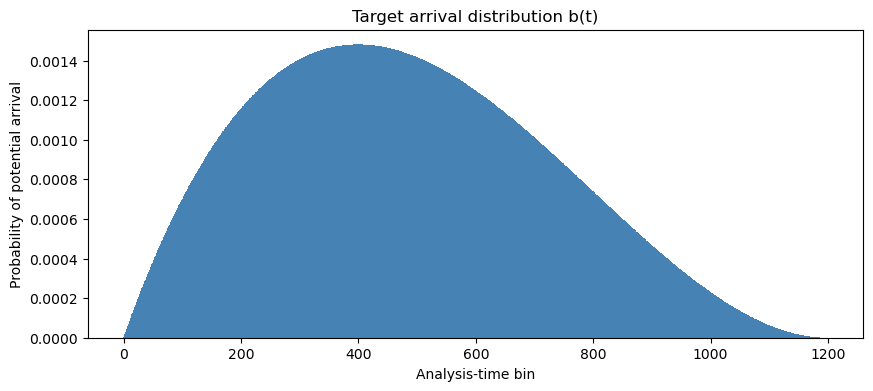

In [12]:
# Bin midpoints are used to avoid evaluating the Beta density exactly at 0 or 1.
bin_numbers = np.arange(N_BINS)
time_fraction = (bin_numbers + 0.5) / N_BINS

raw_b = beta_distribution.pdf(time_fraction, ALPHA, BETA)
b_t = raw_b / raw_b.sum()

assert np.isclose(b_t.sum(), 1.0)

plt.figure(figsize=(10, 4))
plt.bar(bin_numbers, b_t, width=1.0, color='steelblue')
plt.xlabel('Analysis-time bin')
plt.ylabel('Probability of potential arrival')
plt.title('Target arrival distribution b(t)')
plt.show()

## 3. Simulate one IFCB sample

First, draw the latent number of target particles and assign each one an arrival bin using `b_t`. Then process the arrivals sequentially through the IFCB.

`active[t]` records whether the IFCB can image during bin `t`. If a target is imaged in bin `t`, bin `t+1` is inhibited. A potential arrival during an inhibited bin is missed and does not trigger a new inhibition period in this toy model.

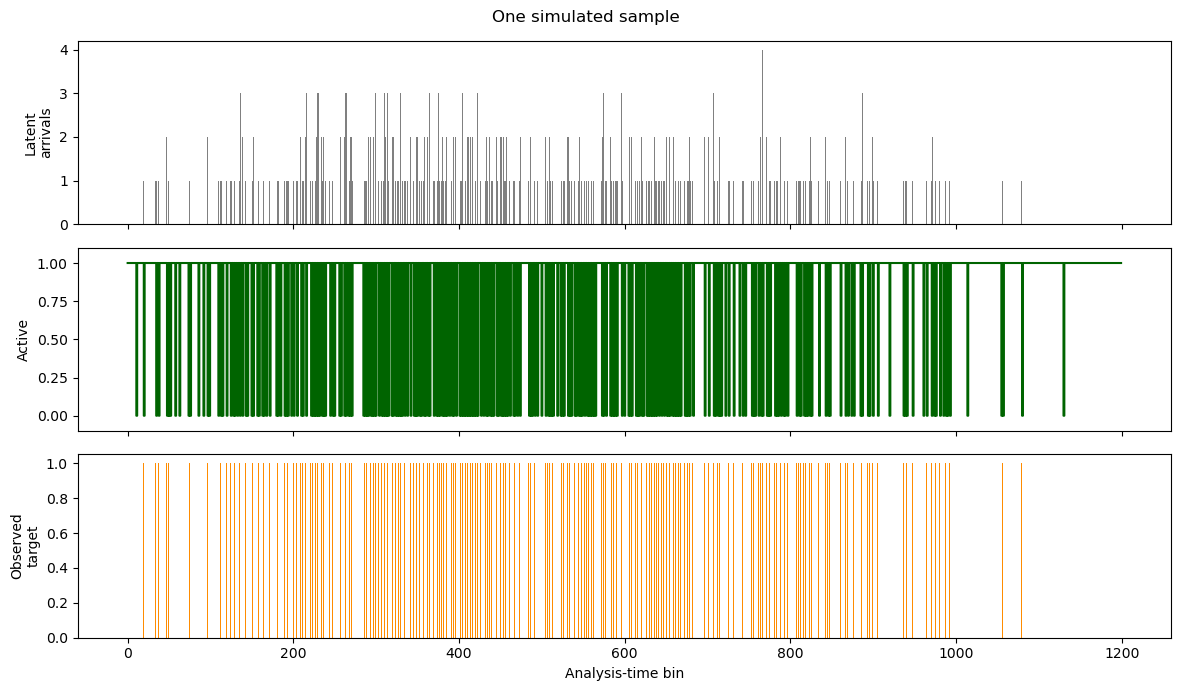

In [13]:
def simulate_one_sample(mu, b_t, rng):
    """Simulate latent arrivals and observed IFCB detections for one sample."""
    n_latent = rng.poisson(mu)
    latent_counts = np.bincount(
        rng.choice(len(b_t), size=n_latent, p=b_t),
        minlength=len(b_t),
    )

    active = np.ones(len(b_t), dtype=bool)
    observed_target = np.zeros(len(b_t), dtype=int)

    for t in range(len(b_t)):
        if active[t] and latent_counts[t] > 0:
            # Collapse multiple target arrivals in one bin to one image.
            observed_target[t] = 1
            if t + 1 < len(b_t):
                active[t + 1] = False
        elif not active[t] and t + 1 < len(b_t):
            # The inhibition lasts exactly one bin. Sampling resumes after it.
            active[t + 1] = True

    return {
        'latent_counts': latent_counts,
        'active': active,
        'observed_target': observed_target,
    }

example_sample = simulate_one_sample(MU_TRUE, b_t, rng)

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axes[0].bar(bin_numbers, example_sample['latent_counts'], color='gray')
axes[0].set_ylabel('Latent\narrivals')
axes[1].step(bin_numbers, example_sample['active'].astype(int), where='mid', color='darkgreen')
axes[1].set_ylabel('Active')
axes[1].set_ylim(-0.1, 1.1)
axes[2].bar(bin_numbers, example_sample['observed_target'], color='darkorange')
axes[2].set_ylabel('Observed\ntarget')
axes[2].set_xlabel('Analysis-time bin')
fig.suptitle('One simulated sample')
plt.tight_layout()
plt.show()

## 4. Simulate an aggregate dataset

Each row represents one sample. The columns contain the active/inactive history and the observed target detections for that sample.

In [14]:
samples = [simulate_one_sample(MU_TRUE, b_t, rng) for _ in range(N_SAMPLES)]
active_matrix = np.vstack([s['active'] for s in samples])
observed_matrix = np.vstack([s['observed_target'] for s in samples])
latent_matrix = np.vstack([s['latent_counts'] for s in samples])

observed_counts = observed_matrix.sum(axis=1)
active_bins = active_matrix.sum(axis=1)

summary = pd.DataFrame({
    'observed_target_count': observed_counts,
    'active_bins': active_bins,
    'active_fraction': active_bins / N_BINS,
})

summary.head()

,observed_target_count,active_bins,active_fraction
0,287,913,0.760833
1,299,901,0.750833
2,295,905,0.754167
3,308,892,0.743333
4,289,911,0.759167


## 5. Compare simple concentration estimates

The naive estimate ignores inhibition. The total-active-time estimate corrects only for the fraction of time the IFCB was active. It assumes target arrivals are uniform over time.

In [15]:
# Naive estimate: observed target count divided by the number of samples and sample volume.
mu_naive = observed_counts.sum() / N_SAMPLES
c_naive = mu_naive / SAMPLE_VOLUME_ML

# Standard-style correction: divide by the average active fraction.
mean_active_fraction = active_fraction = active_bins.mean() / N_BINS
mu_active_time = mu_naive / mean_active_fraction
c_active_time = mu_active_time / SAMPLE_VOLUME_ML

print(f'True mean particles/sample: {MU_TRUE:.4f}')
print(f'Naive estimated particles/sample: {mu_naive:.4f}')
print(f'Active-time corrected particles/sample: {mu_active_time:.4f}')
print()
print(f'True concentration: {MU_TRUE / SAMPLE_VOLUME_ML:.4f} particles/mL')
print(f'Naive concentration: {c_naive:.4f} particles/mL')
print(f'Active-time corrected concentration: {c_active_time:.4f} particles/mL')

True mean particles/sample: 600.0000
Naive estimated particles/sample: 299.9000
Active-time corrected particles/sample: 399.8222

True concentration: 120.0000 particles/mL
Naive concentration: 59.9800 particles/mL
Active-time corrected concentration: 79.9644 particles/mL


## 6. Calculate each sample's target-specific observable fraction

For sample `j`, calculate:

\[r_j = \sum_t b_t A_{jt}\]

This measures how much of the target's expected arrival distribution occurred while the IFCB was active. Unlike total active time, it gives more weight to active periods when this target is most likely to arrive.

In [17]:
target_observable_fraction = active_matrix @ b_t

comparison = pd.DataFrame({
    'active_time_fraction': active_bins / N_BINS,
    'target_observable_fraction': target_observable_fraction,
    'observed_target_count': observed_counts,
})

comparison.head()

,active_time_fraction,target_observable_fraction,observed_target_count
0,0.760833,0.689873,287
1,0.750833,0.679564,299
2,0.754167,0.685108,295
3,0.743333,0.669952,308
4,0.759167,0.683986,289


## 7. Likelihood-based estimate

For the sequential likelihood, the probability of observing at least one target in active bin `t` is:

\[p_t(\mu)=1-\exp(-\mu b_t)\]

where `mu` is the expected number of target particles per sample before inhibition. Inactive bins do not contribute negative evidence because the IFCB could not observe during those bins.

In [18]:
def log_likelihood_mu(mu, observed_matrix, active_matrix, b_t):
    """Sequential Bernoulli log-likelihood conditional on active intervals."""
    if mu <= 0:
        return -np.inf

    p_t = 1.0 - np.exp(-mu * b_t)
    p_t = np.clip(p_t, 1e-15, 1 - 1e-15)

    # Only active intervals contribute. Inactive intervals are unobservable,
    # so they are not treated as failed target detections.
    active_observed = observed_matrix[active_matrix]
    active_probabilities = np.broadcast_to(p_t, observed_matrix.shape)[active_matrix]

    return np.sum(
        active_observed * np.log(active_probabilities)
        + (1 - active_observed) * np.log1p(-active_probabilities)
    )

result = minimize_scalar(
    lambda mu: -log_likelihood_mu(mu, observed_matrix, active_matrix, b_t),
    bounds=(1e-9, 20000.0),
    method='bounded',
)

mu_mle = result.x
c_mle = mu_mle / SAMPLE_VOLUME_ML

print(f'Likelihood estimate, particles/sample: {mu_mle:.4f}')
print(f'Likelihood estimate, particles/mL: {c_mle:.4f}')
print(f'Optimization successful: {result.success}')

Likelihood estimate, particles/sample: 600.2656
Likelihood estimate, particles/mL: 120.0531
Optimization successful: True


## 8. Compare the estimates

The estimates will vary because this is a finite simulation. Re-running with more samples should reduce random variation. The likelihood method should be especially useful when the arrival distribution is strongly nonuniform and inhibition occurs preferentially during high-probability arrival periods.

In [19]:
estimates = pd.DataFrame({
    'method': [
        'True value',
        'Naive',
        'Total active-time correction',
        'Arrival-aware likelihood',
    ],
    'particles_per_sample': [MU_TRUE, mu_naive, mu_active_time, mu_mle],
    'particles_per_mL': [
        MU_TRUE / SAMPLE_VOLUME_ML,
        c_naive,
        c_active_time,
        c_mle,
    ],
})

estimates

,method,particles_per_sample,particles_per_mL
0,True value,600.000000,120.000000
1,Naive,299.900000,59.980000
2,Total active-time correction,399.822242,79.964448
3,Arrival-aware likelihood,600.265557,120.053111


## 8.5. Make the volume correction explicit

The standard IFCB calculation converts active analysis time into effective analyzed volume. In this toy example, the nominal flow rate is the 5 mL sample divided by the 100-bin analysis duration.

The standard effective volume uses only the total active fraction. The target-specific effective volume weights active time by `b_t`. This is the central difference between the conventional correction and the proposed arrival-aware correction.

In [20]:
# In the real instrument, the 1200-second run analyzes a nominal 5 mL sample.
# Here, the same relationship is expressed in toy bins.
RUN_DURATION_SECONDS = 1200.0
BIN_DURATION_SECONDS = RUN_DURATION_SECONDS / N_BINS
FLOW_RATE_ML_PER_SECOND = SAMPLE_VOLUME_ML / RUN_DURATION_SECONDS

# Standard IFCB effective volume: flow rate multiplied by active time.
active_time_seconds = active_bins * BIN_DURATION_SECONDS
standard_effective_volume_ml = FLOW_RATE_ML_PER_SECOND * active_time_seconds

# Arrival-aware effective volume: active time is weighted by the target's b(t).
# When b(t) is uniform, this reduces to the standard effective volume.
target_effective_volume_ml = SAMPLE_VOLUME_ML * target_observable_fraction

# Count-based estimates using each sample's corresponding effective volume.
c_standard_volume = observed_counts.sum() / standard_effective_volume_ml.sum()
c_arrival_weighted_volume = observed_counts.sum() / target_effective_volume_ml.sum()

volume_comparison = pd.DataFrame({
    'standard_effective_volume_ml': standard_effective_volume_ml,
    'target_effective_volume_ml': target_effective_volume_ml,
    'observed_target_count': observed_counts,
})

print(f'Flow rate: {FLOW_RATE_ML_PER_SECOND:.6f} mL/s')
print(f'Total standard effective volume: {standard_effective_volume_ml.sum():.3f} mL')
print(f'Total target-specific effective volume: {target_effective_volume_ml.sum():.3f} mL')
print()
print(f'Standard effective-volume concentration: {c_standard_volume:.4f} particles/mL')
print(f'Arrival-weighted volume concentration: {c_arrival_weighted_volume:.4f} particles/mL')

volume_comparison.head()

Flow rate: 0.004167 mL/s
Total standard effective volume: 750.083 mL
Total target-specific effective volume: 679.229 mL

Standard effective-volume concentration: 79.9644 particles/mL
Arrival-weighted volume concentration: 88.3060 particles/mL


,standard_effective_volume_ml,target_effective_volume_ml,observed_target_count
0,3.804167,3.449367,287
1,3.754167,3.397820,299
2,3.770833,3.425540,295
3,3.716667,3.349760,308
4,3.795833,3.419932,289


## 9. A useful stress test

To demonstrate why inhibition timing matters, the next experiment should compare samples with similar total active time but different inhibition timing. For example:

- early inhibition, when the target arrival probability is high;
- late inhibition, when the target arrival probability is low.

The total-active-time correction treats these samples similarly. The arrival-aware correction should not.

## 10. Extensions toward real IFCB data

After this toy model works, add complexity one feature at a time:

1. Use real inhibition durations instead of one-bin inhibition.
2. Allow inhibition to be triggered by all particle classes, not just the target.
3. Estimate `b_t` from reference observations rather than specifying a Beta distribution.
4. Compare a Beta distribution with an empirical histogram or smooth curve.
5. Allow concentration to differ among samples.
6. Add classification sensitivity and false-positive rates.
7. Propagate uncertainty in `b_t`.
8. Validate against simulated samples with known concentration and, ideally, controlled samples.

A crucial validation is to compare two samples with the same total inhibit time but different inhibition timing.

## Comparing across beta distribs

In [30]:
def compare_beta_distributions(beta_pairs, n_bins=None, n_samples=None,
                                sample_volume_ml=None, mu_true=None,
                                random_seed=None,
                                make_plot=True):
    """Compare all estimators across several Beta arrival distributions."""
    n_bins = N_BINS if n_bins is None else n_bins
    n_samples = N_SAMPLES if n_samples is None else n_samples
    sample_volume_ml = SAMPLE_VOLUME_ML if sample_volume_ml is None else sample_volume_ml
    mu_true = MU_TRUE if mu_true is None else mu_true
    random_seed = RANDOM_SEED if random_seed is None else random_seed

    rows = []
    child_seeds = np.random.SeedSequence(random_seed).spawn(len(beta_pairs))

    for (alpha, beta), child_seed in zip(beta_pairs, child_seeds):
        local_rng = np.random.default_rng(child_seed)
        time_fraction = (np.arange(n_bins) + 0.5) / n_bins
        raw_b = beta_distribution.pdf(time_fraction, alpha, beta)
        local_b_t = raw_b / raw_b.sum()

        local_samples = [simulate_one_sample(mu_true, local_b_t, local_rng)
                         for _ in range(n_samples)]
        local_active = np.vstack([s['active'] for s in local_samples])
        local_observed = np.vstack([s['observed_target'] for s in local_samples])

        counts = local_observed.sum(axis=1)
        active_fraction = local_active.sum(axis=1) / n_bins
        target_fraction = local_active @ local_b_t

        mu_naive_local = counts.sum() / n_samples
        mu_active_local = mu_naive_local / active_fraction.mean()
        mu_volume_local = counts.sum() / target_fraction.sum()

        # Keep the bound well above the expected value; the original bound
        # of 20 forces the MLE to 20 when MU_TRUE is around 600.
        mu_upper = max(20.0, 5.0 * mu_true, 5.0 * mu_naive_local)
        local_result = minimize_scalar(
            lambda mu: -log_likelihood_mu(mu, local_observed, local_active, local_b_t),
            bounds=(1e-9, mu_upper), method='bounded'
        )

        rows.append({
            'alpha': alpha, 'beta': beta, 'mu_true': mu_true,
            'concentration_true': mu_true / sample_volume_ml,
            'concentration_naive': mu_naive_local / sample_volume_ml,
            'concentration_active_time': mu_active_local / sample_volume_ml,
            'concentration_arrival_volume': mu_volume_local / sample_volume_ml,
            'concentration_likelihood': local_result.x / sample_volume_ml,
            'mean_active_fraction': active_fraction.mean(),
            'mean_target_observable_fraction': target_fraction.mean(),
            'likelihood_hit_upper_bound': np.isclose(local_result.x, mu_upper),
        })

    results = pd.DataFrame(rows)

    if make_plot:
        methods = {
            'concentration_true': 'True',
            #'concentration_naive': 'Naive',
            'concentration_active_time': 'Total active-time',
            #'concentration_arrival_volume': 'Arrival-weighted volume',
            'concentration_likelihood': 'Arrival-aware likelihood',
        }
        ax = results.set_index(results.apply(
            lambda row: f"alpha={row['alpha']}, beta={row['beta']}", axis=1
        ))[list(methods)].plot(kind='bar', figsize=(12, 5))
        ax.set_ylabel('Concentration (particles/mL)')
        ax.set_xlabel('Arrival distribution')
        ax.set_title('IFCB estimator comparison across Beta distributions')
        ax.legend([methods[column] for column in methods])
        plt.xticks(rotation=30, ha='right')
        plt.tight_layout()
        plt.show()

    return results

# Example, to run after the simulation functions have been defined:
# beta_comparison = compare_beta_distributions([(1, 1), (2, 5), (5, 2), (2, 2)])
# beta_comparison

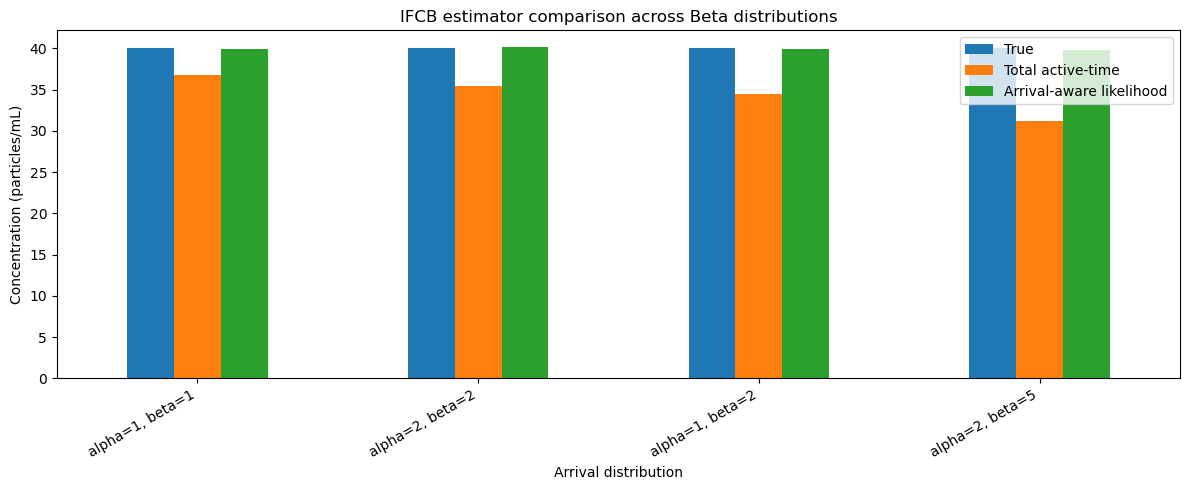

,alpha,beta,mu_true,concentration_true,concentration_naive,concentration_active_time,concentration_arrival_volume,concentration_likelihood,mean_active_fraction,mean_target_observable_fraction,likelihood_hit_upper_bound
0,1,1,200,40.0,31.920,36.812717,36.812717,39.962589,0.867092,0.867092,False
1,2,2,200,40.0,30.921,35.493952,36.453962,40.176079,0.871163,0.848221,False
2,1,2,200,40.0,30.121,34.443846,35.930150,39.944210,0.874496,0.838321,False
3,2,5,200,40.0,27.655,31.256681,34.585074,39.854149,0.884771,0.799622,False


In [34]:
beta_comparison = compare_beta_distributions([(1, 1), (2, 2), (1, 2), (2, 5)], mu_true = 200)
beta_comparison